# Chapter 98: Austrian, Institutional, and Evolutionary Political Economy

This notebook reruns four worked examples from the chapter: cheap credit and long projects, arbitrage profit and imitation, prices that draw on dispersed costs, and who gains from new money first. Every number is one of the chapter's hypothetical values, not data; a few extra input values are added.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def present_value(fv, r, T):
    """fv / (1 + r)^T."""
    return fv / (1.0 + r) ** T


def intermediary_profit(q, p, c, f):
    """Arbitrage profit pi = q (p - c) - f.

    entrepreneurial-discovery (chapter 98): 800 (1.10 - 0.30) = 640 spread, profit 240;
    800 (0.95 - 0.40) - 320 = 120. Implemented by Part 10 (chapter 98 is its first user).
    """
    spread = q * (p - c)
    return {"spread": spread, "profit": spread - f}


def merit_order(costs, capacities, need):
    """Cheapest-first dispatch of `need` units; returns quantities, total cost and the marginal cost band.

    dispersed-knowledge-problem (chapter 98): costs (20, 50, 90), 4 each, need 6 give quantities
    (4, 2, 0) and cost 4(20) + 2(50) = 180. Implemented by Part 10 (chapter 98 is its first user).
    """
    order = sorted(range(len(costs)), key=lambda i: costs[i])
    q = [0.0] * len(costs)
    left = need
    marginal = None
    for i in order:
        take = min(capacities[i], left)
        q[i] = take
        left -= take
        if take > 0:
            marginal = costs[i]
        if left <= 0:
            break
    nxt = [costs[i] for i in order if q[i] < capacities[i] and costs[i] > (marginal or 0)]
    return {"q": q, "cost": sum(qi * ci for qi, ci in zip(q, costs)), "marginal": marginal,
            "next": min(nxt) if nxt else None, "shortfall": max(left, 0)}


def first_round_price(spending, dM, quantity):
    """First-round price when new money dM adds to spending on a fixed quantity: (spending + dM) / quantity.

    cantillon-effects (chapter 98): land 10,000 + 1,000 over 100 claims gives 110; food 10,000 + 1,000
    over 1,000 baskets gives 11, a 1 - 10 / 11 = 9.1 percent food loss for nonrecipients.
    Implemented by Part 10 (chapter 98 is its first user).
    """
    return (spending + dM) / quantity


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(present_value=present_value)


industrial = SimpleNamespace(intermediary_profit=intermediary_profit)


equilibrium = SimpleNamespace(merit_order=merit_order)


macro = SimpleNamespace(first_round_price=first_round_price)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'austrian-malinvestment-cycle': {'cost': 100,
                                  'short': 112,
                                  'long': 140,
                                  'T_long': 4,
                                  'r': 0.1,
                                  'pv_short': 101.82,
                                  'pv_long': 95.62,
                                  'r_low': 0.06,
                                  'pv_short_low': 105.66,
                                  'pv_long_low': 110.89,
                                  'pv_year2': 115.7},
 'entrepreneurial-discovery': {'q': 800,
                               'pg': 0.3,
                               'pc': 1.1,
                               'f': 400,
                               'spread': 640,
                               'profit': 240,
                               'grower_gain': 160,
                               'disposal': 0.1,
                               'wtp': 1.5,
                               'pg_rival': 0.4,
                               'pc_rival': 0.95,
                               'f_rival': 320,
                               'profit_rival': 120},
 'dispersed-knowledge-problem': {'costs': [20, 50, 90],
                                 'caps': [4, 4, 4],
                                 'need': 6,
                                 'price': 55,
                                 'cost_price': 180,
                                 'cost_uniform': 320},
 'cantillon-effects': {'land_claims': 100,
                       'land_price': 100,
                       'baskets': 1000,
                       'food_price': 10,
                       'dM': 1000,
                       'land_after': 110,
                       'food_after': 11,
                       'food_loss_pct': 9.1},
 'constructed': {'austrian-malinvestment-cycle': {'r': [0.08], 'long': [130]},
                 'dispersed-knowledge-problem': {'need': [4, 8]},
                 'cantillon-effects': {'dM': [500, 2000]}}}


LABEL = "Hypothetical teaching numbers, not data."


def credit_picture(r=0.10, pay=140):
    b = BV["austrian-malinvestment-cycle"]
    cost = b["cost"]
    pv_s = choice.present_value(b["short"], r, 1)
    pv_l = choice.present_value(pay, r, b["T_long"])
    fig, ax = new_figure()
    bar_compare(ax, ["Short project (1 year)", "Long project (4 years)"], [pv_s, pv_l], colors=["teal", "navy"],
                value_labels=["", ""], ylabel="Present value ($)", xlabel="Project")
    for x, v in ((0, pv_s), (1, pv_l)):
        label(ax, x, v / 2, money(v), dx=0, dy=0, ha="center", va="center")
    hline(ax, cost, "cost $100", col="terracotta")
    ax.set_ylim(0, 135)
    started = [n for n, v in (("short", pv_s), ("long", pv_l)) if v >= cost]
    started_text = {0: "neither project", 1: f"only the {started[0]} project" if started else "",
                    2: "both projects"}[len(started)]
    metrics = {"PV short": money(pv_s), "PV long": money(pv_l), "Projects started": started_text.capitalize()}
    steps = [f"PV short = 112 / {num(1 + r)} = {money(pv_s)}",
             f"PV long = {pay} / {num(1 + r)}^4 = {pay} / {num((1 + r) ** 4, 4)} = {money(pv_l)}",
             f"Against cost $100: {started_text} {'cover' if len(started) == 2 else 'covers'} {'their' if len(started) == 2 else 'its'} cost"]
    interp = (f"{LABEL} At {pct(r, 0)} the short project is worth 112 / {num(1 + r)} = {num(pv_s)} dollars and the long "
              f"one {pay} / {num((1 + r) ** 4, 4)} = {num(pv_l)} dollars, so {started_text} {'cover' if len(started) == 2 else 'covers'} the $100 cost. A lower rate raises the "
              f"distant payoff's value most, which is why cheap credit lengthens production plans.")
    alt = (f"Two bars against a $100 cost line: short project {money(pv_s)}, long project {money(pv_l)} at "
           f"{pct(r, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def discovery_picture(pg=0.30, pc=1.10, f=400):
    b = BV["entrepreneurial-discovery"]
    q = b["q"]
    r = industrial.intermediary_profit(q, pc, pg, f)
    grower = q * (pg - b["disposal"])
    buyer = q * (b["wtp"] - pc)
    fig, ax = new_figure()
    vals = [r["spread"], f, r["profit"], grower, buyer]
    bar_compare(ax, ["Spread", "Route cost", "Profit", "Grower gain", "Buyer saving"], vals,
                colors=["grey", "terracotta", "teal", "gold", "navy"], value_labels=[money(v, 0) for v in vals],
                ylabel="Dollars per week", xlabel="Item")
    ax.set_ylim(0, 820)
    metrics = {"Spread revenue": money(r["spread"], 0), "Profit": money(r["profit"], 0),
               "Grower gain over disposal": money(grower, 0), "Restaurant saving": money(buyer, 0)}
    steps = [f"Spread = 800 x ({num(pc)} - {num(pg)}) = 800 x {num(pc - pg)} = {money(r['spread'], 0)}",
             f"Profit = {money(r['spread'], 0)} - {money(f, 0)} = {money(r['profit'], 0)}",
             f"Grower gain = 800 x ({num(pg)} - 0.10) = {money(grower, 0)}",
             f"Restaurant saving = 800 x (1.50 - {num(pc)}) = {money(buyer, 0)}"]
    interp = (f"{LABEL} Buying at {money(pg)} and selling at {money(pc)} moves 800 kilograms, and the entrepreneur keeps "
              f"800 x {num(pc - pg)} - {f} = {num(r['profit'], 0)} dollars a week. "
              f"Growers gain {money(grower, 0)} over disposal and restaurants save {money(buyer, 0)}. Imitation "
              f"narrows the spread and passes more of the gain to both sides.")
    alt = (f"Bars: spread {money(r['spread'], 0)}, route cost {money(f, 0)}, profit {money(r['profit'], 0)}, grower "
           f"gain {money(grower, 0)}, restaurant saving {money(buyer, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def knowledge_picture(need=6, mech="price"):
    b = BV["dispersed-knowledge-problem"]
    costs, caps = b["costs"], b["caps"]
    if mech == "price":
        r = equilibrium.merit_order(costs, caps, need)
        q, cost = r["q"], r["cost"]
    else:
        q = [need / 3.0] * 3
        cost = sum(qi * ci for qi, ci in zip(q, costs))
    fig, ax = new_figure()
    left = 0.0
    names = ["A", "B", "C"]
    for i, (c, k) in enumerate(zip(costs, caps)):
        ax.bar(left, c, width=k, align="edge", color=PALETTE["grey"], alpha=0.25, edgecolor=PALETTE["grey"])
        if q[i] > 0:
            ax.bar(left, c, width=q[i], align="edge", color=PALETTE["teal"])
        label(ax, left + k / 2, c, f"{names[i]}: ${c}, uses {num(q[i])}", dx=0, dy=4, ha="center")
        left += k
    ax.set_xlim(0, 12.5)
    ax.set_ylim(0, 115)
    ax.set_xlabel("Curtailment capacity in cost order (MWh)")
    ax.set_ylabel(r"Cost per MWh (\$)")
    if mech == "price":
        band = f"{r['marginal']} and {r['next']}" if r["next"] else None
        steps = [" + ".join(f"{num(qi, 0)} x {c}" for qi, c in zip(q, costs) if qi > 0) + f" = {num(cost)}",
                 (f"A scarcity payment between {band} per MWh elicits exactly {need} MWh" if band else f"A scarcity payment of at least {r['marginal']} per MWh elicits {need} MWh")]
        how = (f"a scarcity payment between {band} per MWh" if band else f"a scarcity payment of at least {r['marginal']} per MWh") + " calls on the cheapest plants first"
    else:
        steps = [f"Each plant: {need} / 3 = {num(need / 3)} MWh",
                 f"Cost = ({need} / 3) x (20 + 50 + 90) = {need} x 160 / 3 = {num(cost)}"]
        how = f"assigning {num(need / 3)} MWh to every plant ignores their different costs"
    price_cost = equilibrium.merit_order(costs, caps, need)["cost"]
    metrics = {"Mechanism": "Scarcity price" if mech == "price" else "Equal assignment", "Total cost": money(cost),
               "Cost with a scarcity price": money(price_cost), "Extra cost": money(cost - price_cost)}
    calc = steps[0] if mech == "price" else f"({need} / 3) x 160 = {num(cost)}"
    interp = (f"{LABEL} To curtail {need} MWh, {how}; the resource cost is {calc} dollars, against "
              f"{money(price_cost)} with a price. The price works because it draws on costs only each plant knows.")
    alt = (f"Step cost curve for plants A ($20), B ($50) and C ($90), 4 MWh each; shaded blocks show who curtails "
           f"{need} MWh, total cost {money(cost)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def cantillon_picture(dm=1000, path="land"):
    b = BV["cantillon-effects"]
    land0, food0 = b["land_price"], b["food_price"]
    land_sp, food_sp = land0 * b["land_claims"], food0 * b["baskets"]
    if path == "land":
        land1, food1 = macro.first_round_price(land_sp, dm, b["land_claims"]), food0
    else:
        land1, food1 = land0, macro.first_round_price(food_sp, dm, b["baskets"])
    loss = 1 - food0 / food1
    fig, ax = new_figure()
    xs = np.arange(2)
    before = [100.0, 100.0]
    after = [100 * land1 / land0, 100 * food1 / food0]
    ax.bar(xs - 0.18, before, width=0.34, color=PALETTE["grey"], label="before")
    ax.bar(xs + 0.18, after, width=0.34, color=PALETTE["terracotta"], label="after first round")
    label(ax, -0.18, 100, money(land0), dx=0, dy=3, ha="center", box=False)
    label(ax, 0.82, 100, money(food0), dx=0, dy=3, ha="center", box=False)
    label(ax, 0.18, after[0], money(land1), dx=0, dy=3, ha="center", box=False)
    label(ax, 1.18, after[1], money(food1), dx=0, dy=3, ha="center", box=False)
    ax.set_xticks(xs, ["Land claim", "Food basket"])
    ax.set_ylim(0, 150)
    ax.set_ylabel("Price index (start = 100)")
    ax.set_xlabel("Good")
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    who = "land investors" if path == "land" else "households"
    spent = "land" if path == "land" else "food"
    metrics = {"Land price": money(land1), "Food basket price": money(food1),
               "Nonrecipient food loss": pct(loss)}
    if path == "land":
        steps = [f"Land price = (10,000 + {dm:,}) / 100 = {money(land1)}",
                 "Food price stays $10, so nonrecipients lose no food in the first round"]
    else:
        steps = [f"Food price = (10,000 + {dm:,}) / 1,000 = {money(food1)}",
                 f"Nonrecipient loss = 1 - 10 / {num(food1)} = {pct(loss)}"]
    if path == "land":
        calc = f"the land price becomes (10,000 + {dm:,}) / 100 = {num(land1)}"
    else:
        calc = f"the basket price becomes (10,000 + {dm:,}) / 1,000 = {num(food1)}"
    interp = (f"{LABEL} The {money(dm, 0)} goes first to {who}, who spend it on {spent}, so {calc}. Land ends the first round at "
              f"{money(land1)} and food at {money(food1)}, so " + (f"a nonrecipient can buy {pct(loss)} less food." if loss > 0 else "a nonrecipient loses no food in the first round.") + f" The same "
              f"injection changes relative prices differently depending on who receives it first.")
    alt = (f"Price index bars before and after the first round: land {money(land1)}, food {money(food1)} after "
           f"{money(dm, 0)} goes to {who}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Austrian malinvestment cycle: credit terms and the long project

Hypothetical: two projects cost \$100; the short pays \$112 in one year, the long \$140 in four. Credit pushes the loan rate below the saving-consistent rate, $i_m<i_n$, and each payoff is discounted as payoff / (1 + r)^years.

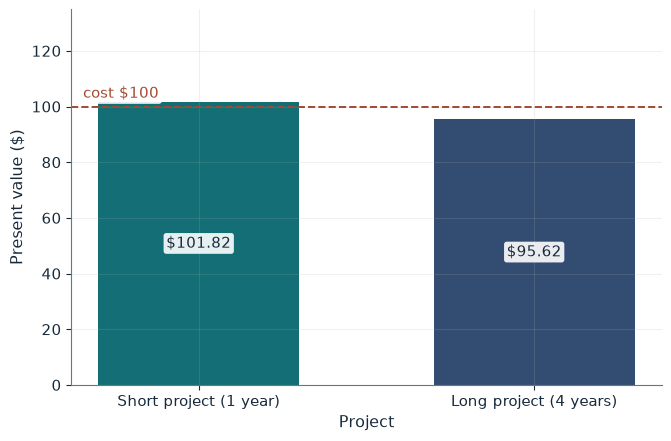

PV short          $101.82
PV long           $95.62
Projects started  Only the short project

Worked steps:
  1. PV short = 112 / 1.10 = $101.82
  2. PV long = 140 / 1.10^4 = 140 / 1.4641 = $95.62
  3. Against cost $100: only the short project covers its cost

Hypothetical teaching numbers, not data. At 10% the short project is worth 112 / 1.10 = 101.82 dollars and the long one 140 / 1.4641 = 95.62 dollars, so only the short project covers the $100 cost. A lower rate raises the distant payoff's value most, which is why cheap credit lengthens production plans.


In [2]:
show(credit_picture(r=0.10, pay=140))

Change one input, `r`, and hold the others at the book's values:

In [3]:
sweep(credit_picture, 'r', [0.06, 0.08, 0.1], {'pay': 140}, ['PV short', 'PV long'])

r | PV short | PV long
0.06 | $105.66 | $110.89
0.08 | $103.70 | $102.90
0.1 | $101.82 | $95.62


At 10% only the short project covers its cost (\$101.82 against \$95.62). At 6% both do, and the long project gains most.

## 2. Entrepreneurial discovery: arbitrage and imitation

Hypothetical: 800 kg a week, growers' disposal value \$0.10, restaurants' maximum \$1.50.

$$\pi=q(p-c)-f$$

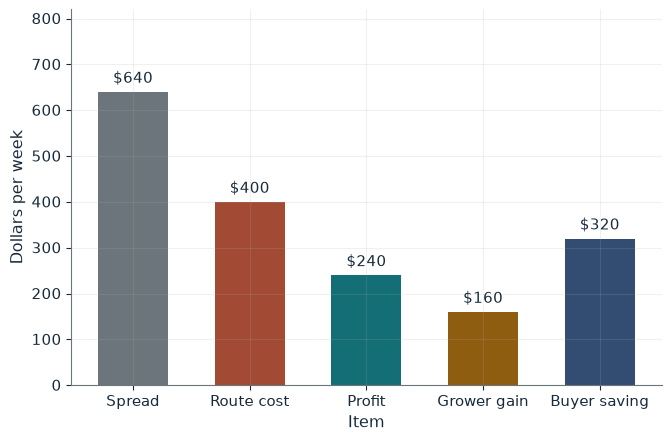

Spread revenue             $640
Profit                     $240
Grower gain over disposal  $160
Restaurant saving          $320

Worked steps:
  1. Spread = 800 x (1.10 - 0.30) = 800 x 0.80 = $640
  2. Profit = $640 - $400 = $240
  3. Grower gain = 800 x (0.30 - 0.10) = $160
  4. Restaurant saving = 800 x (1.50 - 1.10) = $320

Hypothetical teaching numbers, not data. Buying at $0.30 and selling at $1.10 moves 800 kilograms, and the entrepreneur keeps 800 x 0.80 - 400 = 240 dollars a week. Growers gain $160 over disposal and restaurants save $320. Imitation narrows the spread and passes more of the gain to both sides.


In [4]:
show(discovery_picture(pg=0.30, pc=1.10, f=400))

Change one input, `pc`, and hold the others at the book's values:

In [5]:
sweep(discovery_picture, 'pc', [0.95, 1.1], {'pg': 0.4, 'f': 320}, ['Profit'])

pc | Profit
0.95 | $120
1.1 | $240


The first trader earns \$240. After imitation (0.40 and 0.95 on a \$320 route) the profit falls to \$120 while growers and restaurants gain.

## 3. Dispersed-knowledge problem: prices elicit private costs

Hypothetical: plants A, B and C can each curtail 4 MWh at \$20, \$50 and \$90.

Price: 4(20) + 2(50) = 180. Equal assignment: 2(20) + 2(50) + 2(90) = 320.

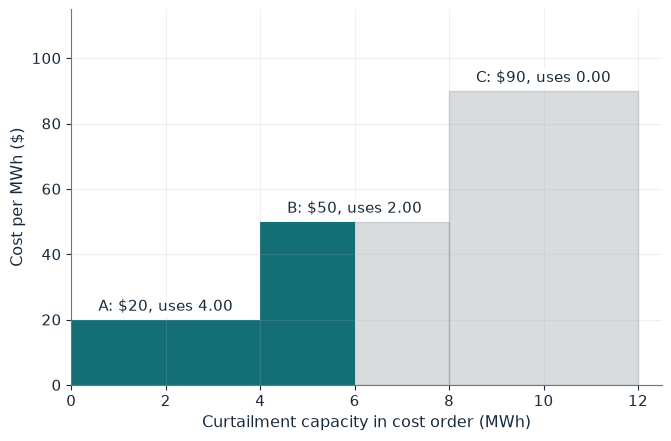

Mechanism                   Scarcity price
Total cost                  $180.00
Cost with a scarcity price  $180.00
Extra cost                  $0.00

Worked steps:
  1. 4 x 20 + 2 x 50 = 180.00
  2. A scarcity payment between 50 and 90 per MWh elicits exactly 6 MWh

Hypothetical teaching numbers, not data. To curtail 6 MWh, a scarcity payment between 50 and 90 per MWh calls on the cheapest plants first; the resource cost is 4 x 20 + 2 x 50 = 180.00 dollars, against $180.00 with a price. The price works because it draws on costs only each plant knows.


In [6]:
show(knowledge_picture(need=6, mech='price'))

Change one input, `need`, and hold the others at the book's values:

In [7]:
sweep(knowledge_picture, 'need', [4, 6, 8], {'mech': 'uniform'}, ['Total cost', 'Extra cost'])

need | Total cost | Extra cost
4 | $213.33 | $133.33
6 | $320.00 | $140.00
8 | $426.67 | $146.67


A scarcity payment between \$50 and \$90 elicits the cheapest 6 MWh for \$180; equal assignment costs \$320.

## 4. Cantillon effects: who gets new money first

Hypothetical: 100 land claims at \$100, 1,000 baskets at \$10, and \$1,000 of new money spent in the first round.

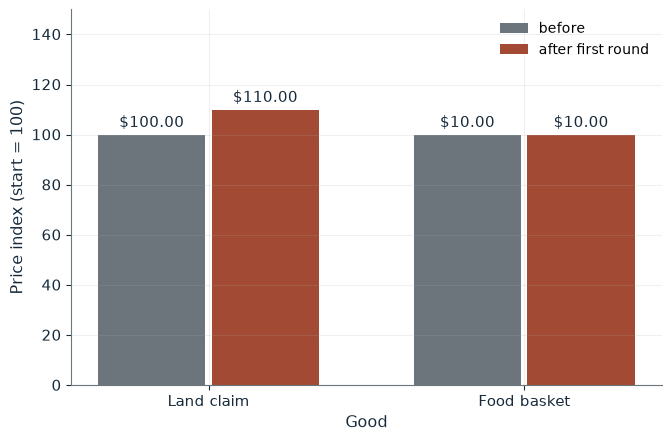

Land price              $110.00
Food basket price       $10.00
Nonrecipient food loss  0.0%

Worked steps:
  1. Land price = (10,000 + 1,000) / 100 = $110.00
  2. Food price stays $10, so nonrecipients lose no food in the first round

Hypothetical teaching numbers, not data. The $1,000 goes first to land investors, who spend it on land, so the land price becomes (10,000 + 1,000) / 100 = 110.00. Land ends the first round at $110.00 and food at $10.00, so a nonrecipient loses no food in the first round. The same injection changes relative prices differently depending on who receives it first.


In [8]:
show(cantillon_picture(dm=1000, path='land'))

Change one input, `path`, and hold the others at the book's values:

In [9]:
sweep(cantillon_picture, 'path', ['land', 'households'], {'dm': 1000}, ['Land price', 'Food basket price', 'Nonrecipient food loss'])

path | Land price | Food basket price | Nonrecipient food loss
land | $110.00 | $10.00 | 0.0%
households | $100.00 | $11.00 | 9.1%


Sent to land investors, the money lifts land to \$110 and leaves food at \$10; sent to households, it lifts baskets to \$11 and nonrecipients buy 9.1% less food.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

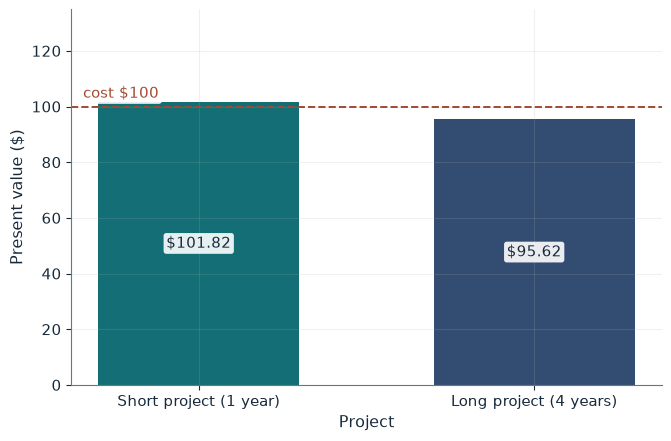

PV short          $101.82
PV long           $95.62
Projects started  Only the short project

Worked steps:
  1. PV short = 112 / 1.10 = $101.82
  2. PV long = 140 / 1.10^4 = 140 / 1.4641 = $95.62
  3. Against cost $100: only the short project covers its cost

Hypothetical teaching numbers, not data. At 10% the short project is worth 112 / 1.10 = 101.82 dollars and the long one 140 / 1.4641 = 95.62 dollars, so only the short project covers the $100 cost. A lower rate raises the distant payoff's value most, which is why cheap credit lengthens production plans.


In [10]:
show(credit_picture(r=0.10, pay=140))

## Practice

**1.** At 8% with payoff 140, which projects pass?

<details><summary>Answer</summary>

Short 112 / 1.08 = 103.70 and long 140 / 1.08^4 = 102.90: both.

</details>

**2.** Grower price \$0.40, restaurant price \$1.10, route \$400: profit?

<details><summary>Answer</summary>

800 x 0.70 - 400 = \$160.

</details>

**3.** With \$2,000 injected to households, what is the basket price and the loss?

<details><summary>Answer</summary>

12,000 / 1,000 = \$12; 1 - 10 / 12 = 16.7%.

</details>